## 1. Import and Load the Data

In [92]:
import numpy as np
import pandas as pd
import scipy

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Supervised regression algorithms
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor,
    AdaBoostRegressor,
    RandomForestRegressor,
)
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor

# Supervised classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    AdaBoostClassifier,
)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis

df= pd.read_excel('data.xlsm')
df.head()


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [93]:
df.describe()


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [94]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


# 2. EDA
## •	Visualize the distribution of each feature
o	Understand correlations (especially with the target variable) <br/>
Check for variables distributions.

C:\Users\rmehta\AppData\Local\Temp\ipykernel_9596\3316049465.py:13: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(


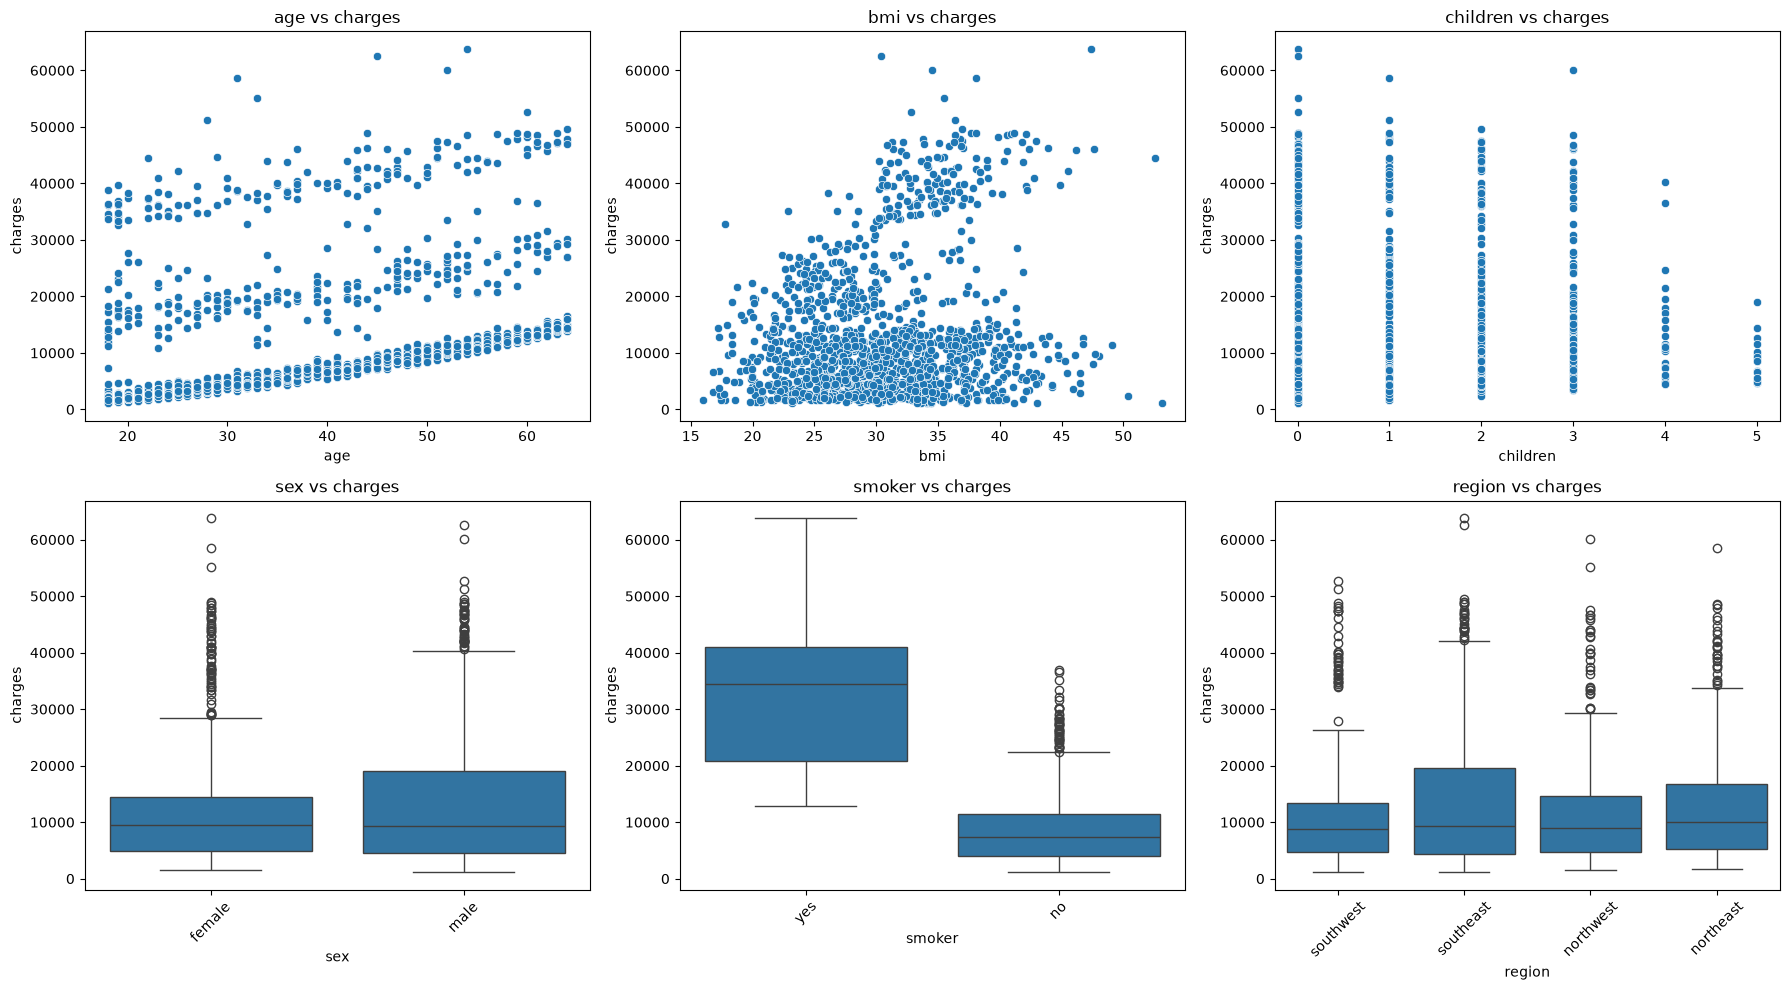

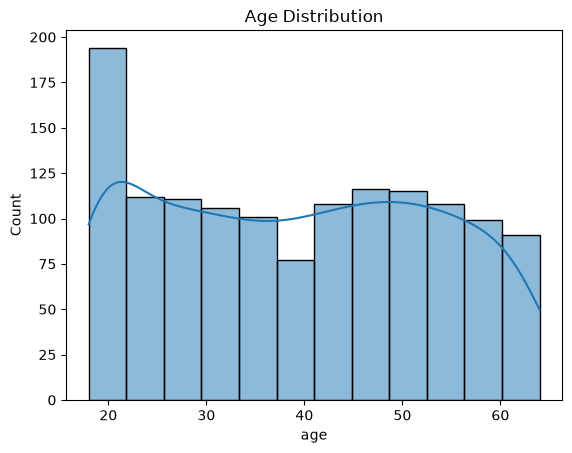

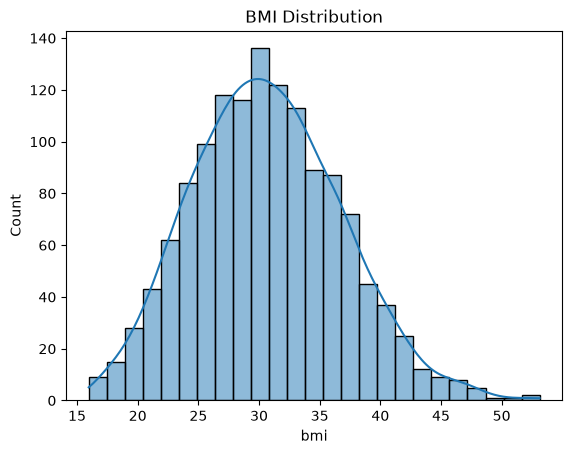

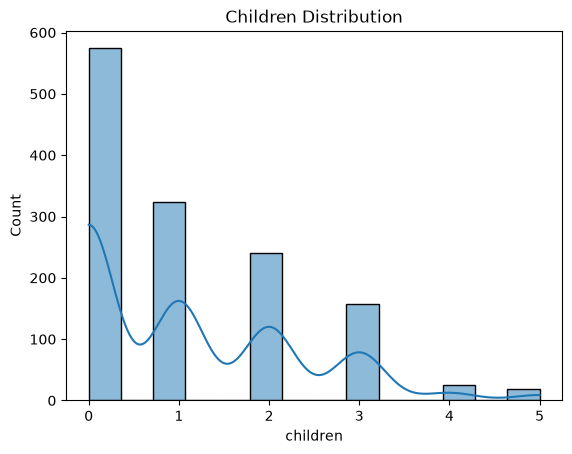

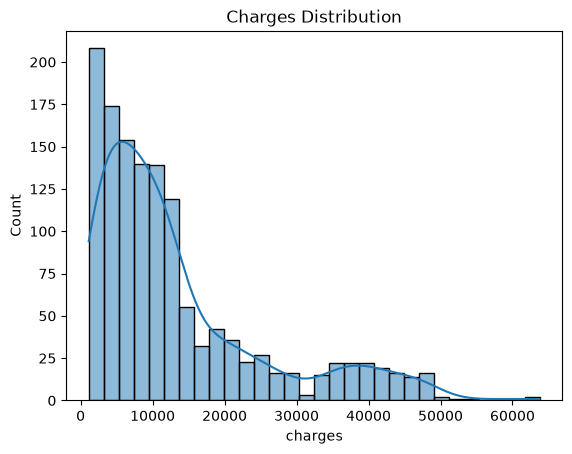

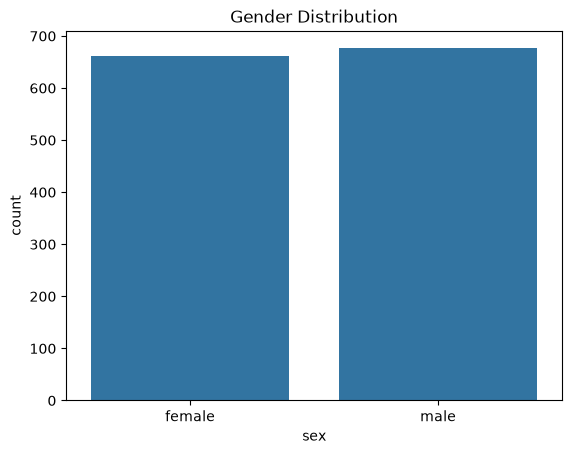

In [95]:
import matplotlib.pyplot as plt
import seaborn as sns

import matplotlib.pyplot as plt
import seaborn as sns
import math

target = 'charges'

# Get numerical and categorical features
numerical_features = df.select_dtypes(include='number').columns.drop(target)

categorical_features = df.select_dtypes(
    include=['object', 'category', 'bool']
).columns

# Combine all features
features = list(numerical_features) + list(categorical_features)

# Create subplots
cols = 3
rows = math.ceil(len(features) / cols)

fig, axes = plt.subplots(
    rows, cols,
    figsize=(18, rows * 5)
)

axes = axes.flatten()

for i, feature in enumerate(features):

    if feature in numerical_features:

        sns.scatterplot(
            data=df,
            x=feature,
            y=target,
            ax=axes[i]
        )

    else:

        sns.boxplot(
            data=df,
            x=feature,
            y=target,
            ax=axes[i]
        )

        axes[i].tick_params(axis='x', rotation=45)

    axes[i].set_title(f'{feature} vs {target}')

# Hide unused plots
for j in range(len(features), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()


sns.histplot(df['age'], kde=True)
plt.title('Age Distribution')
plt.show()

import matplotlib.pyplot as plt
import seaborn as sns
sns.histplot(df['bmi'], kde=True)
plt.title('BMI Distribution')
plt.show()

import matplotlib.pyplot as plt
import seaborn as sns
sns.histplot(df['children'], kde=True)
plt.title('Children Distribution')
plt.show()

import matplotlib.pyplot as plt
import seaborn as sns
sns.histplot(df['charges'], kde=True)
plt.title('Charges Distribution')
plt.show()

sns.countplot(x=df['sex'])
plt.title('Gender Distribution')
plt.show()



## •	Summarize insights from EDA
Charges tend to rise with age, and smokers incur noticeably higher charges than non-smokers. The Southeast shows higher charges than other regions, though this comparison may be influenced by differences in customer characteristics. BMI appears approximately normally distributed. Charges are likely right-skewed, reflecting a smaller number of very high-cost cases. The age distribution has its highest concentration around age 20. Children is rightly skewed, reflecting a more records have no children and very few records have 4 or 5 children.

# 3. Missing Values & Outlier Treatment
### Check for missing values and treat them if any <br>
### Check if there are any outliers

In [96]:
df.isnull().sum() # no missing values in the dataset

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Training set: (1070, 6), Test set: (268, 6)


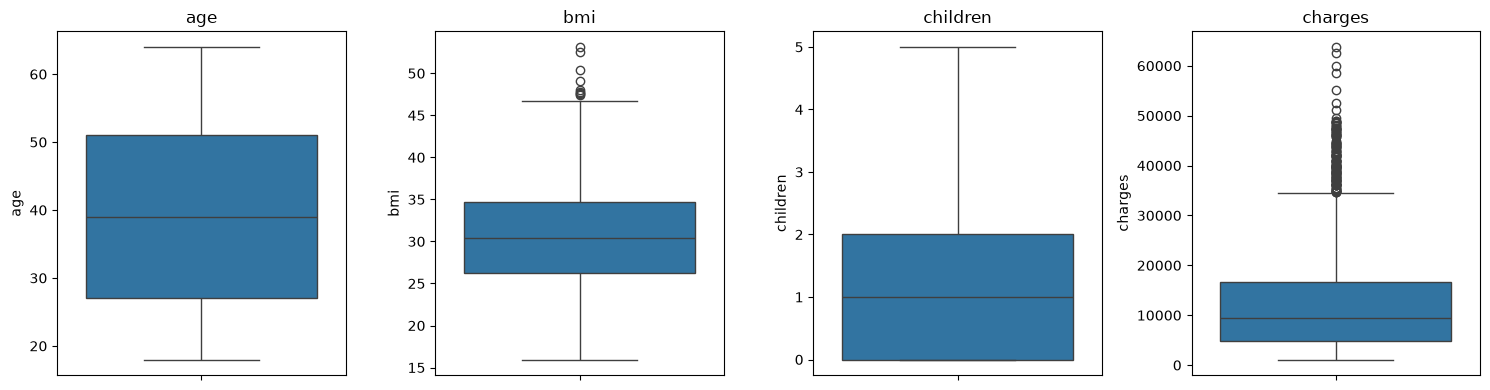

age: 0 values outside [-9.00, 87.00]
bmi: 6 values outside [13.77, 46.93]


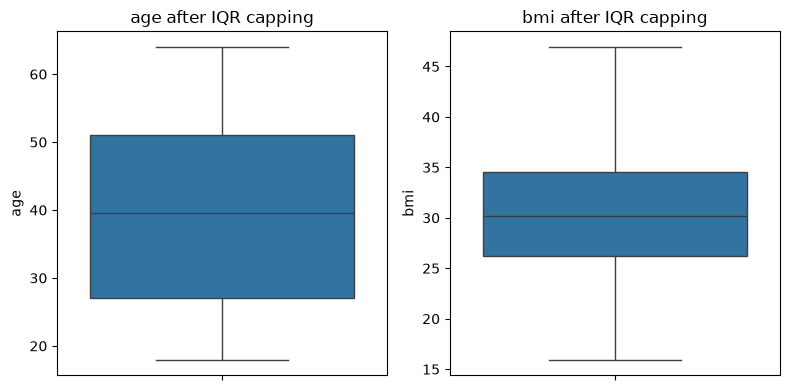

In [97]:
# Split the dataset into features and target variable before outlier treatment
X = df.drop(columns='charges')
y = df['charges']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training set: {X_train.shape}, Test set: {X_test.shape}")

# Inspect numeric features and target for potential outliers
numeric_to_plot = list(numerical_features) + [target]

fig, axes = plt.subplots(1, len(numeric_to_plot), figsize=(15, 4))
for ax, col in zip(axes, numeric_to_plot):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

# IQR-cap continuous predictors; keep the target and discrete child count unchanged
df_treated = X_train.copy()
continuous_predictors = ['age', 'bmi']

for col in continuous_predictors:
    q1 = df_treated[col].quantile(0.25)
    q3 = df_treated[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_count = ((df_treated[col] < lower_bound) |
                     (df_treated[col] > upper_bound)).sum()
    print(f'{col}: {outlier_count} values outside [{lower_bound:.2f}, {upper_bound:.2f}]')

    df_treated[col] = df_treated[col].clip(lower_bound, upper_bound)

# Check the treated predictors
fig, axes = plt.subplots(1, len(continuous_predictors), figsize=(8, 4))
for ax, col in zip(axes, continuous_predictors):
    sns.boxplot(y=df_treated[col], ax=ax)
    ax.set_title(f'{col} after IQR capping')
plt.tight_layout()
plt.show()

# 4. Feature Engineering & Preprocessing
•	Encode categorical variables (sex, smoker, region)
•	Feature scaling for numerical values (StandardScaler / MinMaxScaler)
•	Check for skewness and treat it if required.


In [98]:
df_encoded = pd.get_dummies(
    df_treated,
    columns=['sex', 'smoker', 'region'],
    dtype=int
)

df_encoded.head()

,age,bmi,children,sex_female,sex_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
560,46,19.95,2,1,0,1,0,0,1,0,0
1285,47,24.32,0,1,0,1,0,1,0,0,0
1142,52,24.86,0,1,0,1,0,0,0,1,0
969,39,34.32,5,1,0,1,0,0,0,1,0
486,54,21.47,3,1,0,1,0,0,1,0,0


In [99]:
standard_scaler = StandardScaler()
df_scaled = df_encoded.copy()
df_scaled[numerical_features] = standard_scaler.fit_transform(df_scaled[numerical_features])

df_scaled.head()

,age,bmi,children,sex_female,sex_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
560,0.472227,-1.765942,0.734336,1,0,1,0,0,1,0,0
1285,0.543313,-1.037734,-0.911192,1,0,1,0,1,0,0,0
1142,0.898745,-0.947749,-0.911192,1,0,1,0,0,0,1,0
969,-0.025379,0.628647,3.202629,1,0,1,0,0,0,1,0
486,1.040918,-1.512652,1.557100,1,0,1,0,0,1,0,0


In [100]:
skewness = df_scaled[numerical_features].skew()
print("Skewness of numerical features:\n", skewness)

Skewness of numerical features:
 age         0.027276
bmi         0.221267
children    0.935148
dtype: float64


In [101]:
df_skew_handled = df_treated.copy()
df_skew_handled['children'] = np.log1p(df_skew_handled['children'])

print('Children skewness after log1p:', df_skew_handled['children'].skew())

df_encoded_skew = pd.get_dummies(
    df_skew_handled,
    columns=['sex', 'smoker', 'region'],
    dtype=int
)

df_scaled_skew = df_encoded_skew.copy()
df_scaled_skew[numerical_features] = StandardScaler().fit_transform(
    df_scaled_skew[numerical_features]
)

Children skewness after log1p: 0.2586323896401377


## 5. Model Building: Try Multiple Regressors
## 6. Model Evaluation & Overfitting Check
Use all the regression-based models to train and test the data:
•	Linear Regression
•	Decision Tree Regressor
•	Random Forest Regressor
•	SVR
•	KNN
•	Ensemble Learning methods


In [102]:
preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', StandardScaler(), X_train.select_dtypes(include='number').columns),
        ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False),
         X_train.select_dtypes(exclude='number').columns),
    ]
)

models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(),
    'Lasso': Lasso(),
    'ElasticNet': ElasticNet(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42),
    'SVR': SVR(),
    'KNN': KNeighborsRegressor(),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'AdaBoost': AdaBoostRegressor(random_state=42),
    'XGBoost': XGBRegressor(
        random_state=42,
        n_estimators=300,
        objective='reg:squarederror'
    ),
}

results = []
fitted_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model),
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_train)
    fitted_models[name] = pipeline

    results.append({
        'Model': name,
        'MAE': mean_absolute_error(y_train, predictions),
        'RMSE': np.sqrt(mean_squared_error(y_train, predictions)),
        'R²': r2_score(y_train, predictions),
        'Adjusted R²': 1 - (1 - r2_score(y_train, predictions)) * (len(y_train) - 1) / (len(y_train) - X_train.shape[1] - 1)
    })

results_df = pd.DataFrame(results).sort_values('RMSE').reset_index(drop=True)
results_df

,Model,MAE,RMSE,R²,Adjusted R²
0,Decision Tree,29.572515,494.205984,0.998308,0.998298
1,XGBoost,66.925441,497.442083,0.998286,0.998276
2,Random Forest,1030.901777,1897.942706,0.975043,0.974902
3,Gradient Boosting,2096.939347,3804.240225,0.899731,0.899165
4,KNN,2859.823882,4773.829775,0.842106,0.841215
5,AdaBoost,4258.312557,5173.036354,0.814594,0.813548
6,Linear Regression,4208.234572,6105.545160,0.741726,0.740268
7,Lasso,4208.290808,6105.547748,0.741725,0.740268
8,Ridge,4212.650075,6105.608877,0.741720,0.740262
9,ElasticNet,6270.449164,8516.408186,0.497489,0.494653


### •	Compare performance on both datasets (Training and testing) to detect overfitting

In [116]:
preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', StandardScaler(), X_test.select_dtypes(include='number').columns),
        ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False),
         X_test.select_dtypes(exclude='number').columns),
    ]
)

models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(),
    'Lasso': Lasso(),
    'ElasticNet': ElasticNet(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42),
    'SVR': SVR(),
    'KNN': KNeighborsRegressor(),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'AdaBoost': AdaBoostRegressor(random_state=42),
    'XGBoost': XGBRegressor(
        random_state=42,
        n_estimators=300,
        objective='reg:squarederror'
    ),
}

results_test = []
fitted_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model),
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    fitted_models[name] = pipeline
    print(model.get_params())
    results_test.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, predictions),
        'RMSE': np.sqrt(mean_squared_error(y_test, predictions)),
        'R²': r2_score(y_test, predictions),
        'Adjusted R²': 1 - (1 - r2_score(y_test, predictions)) * (len(y_test) - 1) / (len(y_test) - X_test.shape[1] - 1)
    })

results_test_df = pd.DataFrame(results_test).sort_values('RMSE').reset_index(drop=True)
results_test_df

{'copy_X': True, 'fit_intercept': True, 'n_jobs': None, 'positive': False, 'tol': 1e-06}
{'alpha': 1.0, 'copy_X': True, 'fit_intercept': True, 'max_iter': None, 'positive': False, 'random_state': None, 'solver': 'auto', 'tol': 0.0001}
{'alpha': 1.0, 'copy_X': True, 'fit_intercept': True, 'max_iter': 1000, 'positive': False, 'precompute': False, 'random_state': None, 'selection': 'cyclic', 'tol': 0.0001, 'warm_start': False}
{'alpha': 1.0, 'copy_X': True, 'fit_intercept': True, 'l1_ratio': 0.5, 'max_iter': 1000, 'positive': False, 'precompute': False, 'random_state': None, 'selection': 'cyclic', 'tol': 0.0001, 'warm_start': False}
{'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': None, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 42, 'splitter': 'best'}
{'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_de

,Model,MAE,RMSE,R²,Adjusted R²
0,Gradient Boosting,2400.758193,4324.573905,0.879536,0.876766
1,Random Forest,2545.869462,4585.229941,0.864576,0.861463
2,XGBoost,2910.026490,4968.762808,0.840974,0.837318
3,AdaBoost,4421.259251,5267.060510,0.821307,0.817199
4,Linear Regression,4181.194474,5796.284659,0.783593,0.778618
5,Lasso,4182.081076,5797.054261,0.783536,0.778559
6,Ridge,4186.913072,5798.298795,0.783443,0.778464
7,KNN,3631.591179,5998.687932,0.768215,0.762887
8,Decision Tree,3227.664954,6668.078316,0.713600,0.707016
9,ElasticNet,6513.223507,8636.572305,0.519543,0.508498


In [104]:
# Compare train vs test performance to assess overfitting
train = results_df.copy().rename(columns={
    "MAE": "train_mae",
    "RMSE": "train_rmse",
    "R²": "train_r2",
    "Adjusted R²": "train_adj_r2"
})

test = results_test_df.copy().rename(columns={
    "MAE": "test_mae",
    "RMSE": "test_rmse",
    "R²": "test_r2",
    "Adjusted R²": "test_adj_r2"
})

comparison = train.merge(test, on="Model", how="inner")

# Positive gap means training performance is better than test
comparison["mae_gap"] = comparison["train_mae"] - comparison["test_mae"]
comparison["rmse_gap"] = comparison["train_rmse"] - comparison["test_rmse"]
comparison["r2_gap"] = comparison["train_r2"] - comparison["test_r2"]
comparison["adj_r2_gap"] = comparison["train_adj_r2"] - comparison["test_adj_r2"]

comparison = comparison.sort_values("rmse_gap", ascending=False).reset_index(drop=True)

display(
    comparison[
        [
            "Model",
            "train_mae", "test_mae", "mae_gap",
            "train_rmse", "test_rmse", "rmse_gap",
            "train_r2", "test_r2", "r2_gap",
            "train_adj_r2", "test_adj_r2", "adj_r2_gap"
        ]
    ]
)



,Model,train_mae,test_mae,mae_gap,train_rmse,test_rmse,rmse_gap,train_r2,test_r2,r2_gap,train_adj_r2,test_adj_r2,adj_r2_gap
0,Linear Regression,4208.234572,4181.194474,27.040099,6105.545160,5796.284659,309.260501,0.741726,0.783593,-0.041867,0.740268,0.778618,-0.038350
1,Lasso,4208.290808,4182.081076,26.209732,6105.547748,5797.054261,308.493487,0.741725,0.783536,-0.041810,0.740268,0.778559,-0.038292
2,Ridge,4212.650075,4186.913072,25.737003,6105.608877,5798.298795,307.310082,0.741720,0.783443,-0.041722,0.740262,0.778464,-0.038202
3,AdaBoost,4258.312557,4421.259251,-162.946693,5173.036354,5267.060510,-94.024156,0.814594,0.821307,-0.006712,0.813548,0.817199,-0.003651
4,ElasticNet,6270.449164,6513.223507,-242.774344,8516.408186,8636.572305,-120.164119,0.497489,0.519543,-0.022054,0.494653,0.508498,-0.013845
5,SVR,8249.511497,8605.845654,-356.334158,12573.012379,12892.023995,-319.011616,-0.095245,-0.070568,-0.024677,-0.101427,-0.095178,-0.006248
6,Gradient Boosting,2096.939347,2400.758193,-303.818846,3804.240225,4324.573905,-520.333679,0.899731,0.879536,0.020195,0.899165,0.876766,0.022398
7,KNN,2859.823882,3631.591179,-771.767297,4773.829775,5998.687932,-1224.858157,0.842106,0.768215,0.073890,0.841215,0.762887,0.078327
8,Random Forest,1030.901777,2545.869462,-1514.967686,1897.942706,4585.229941,-2687.287235,0.975043,0.864576,0.110466,0.974902,0.861463,0.113438
9,XGBoost,66.925441,2910.026490,-2843.101049,497.442083,4968.762808,-4471.320724,0.998286,0.840974,0.157312,0.998276,0.837318,0.160958


# 7. Hyperparameter Tuning
•	Use GridSearchCV or RandomizedSearchCV to optimize the best-performing models

In [121]:
from sklearn.model_selection import GridSearchCV

model = GradientBoostingRegressor(random_state=42)

param_grid = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [5, 10, 20],
    'model__min_samples_split': [2, 5]
}
param_grid = {
    'model__n_estimators': [80, 100, 150, 200],
    'model__learning_rate': [0.05, 0.1, 0.15],
    'model__max_depth': [2, 3, 4],
    'model__min_samples_split': [2, 3, 5],
    'model__min_samples_leaf': [1, 2, 4],
    'model__subsample': [0.8, 0.9, 1.0]
}
preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', StandardScaler(), X_test.select_dtypes(include='number').columns),
        ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False),
         X_test.select_dtypes(exclude='number').columns),
    ]
)
pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model),
    ])

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Score:", grid_search.best_score_)

Best Parameters: {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 80, 'model__subsample': 0.9}
Best Score: 0.8506822603560773


In [106]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

model = GradientBoostingRegressor(random_state=42)

preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', StandardScaler(), X_test.select_dtypes(include='number').columns),
        ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False),
         X_test.select_dtypes(exclude='number').columns),
    ]
)

param_dist = {
    'model__n_estimators': randint(100, 500),
    'model__max_depth': [5, 10, 20, None],
    'model__min_samples_split': randint(2, 10)
}

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', model)
])

random_search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_dist,
    n_iter=20,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    random_state=42
)

random_search.fit(X_train, y_train)

print("Best Parameters:", random_search.best_params_)
print("Best Score:", random_search.best_score_)

Best Parameters: {'model__max_depth': 5, 'model__min_samples_split': 6, 'model__n_estimators': 202}
Best Score: 0.8039233963995113


## •	Document best parameters and improvement in performance

In [127]:
#Best Parameters: {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 80, 'model__subsample': 0.9}

best_model = GradientBoostingRegressor(random_state=42, max_depth=2,min_samples_leaf=1, min_samples_split=2, n_estimators=80, learning_rate=0.1, subsample=0.9)

preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', StandardScaler(), X_test.select_dtypes(include='number').columns),
        ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False),
         X_test.select_dtypes(exclude='number').columns),
    ]
)

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', best_model)
])

pipeline.fit(X_train, y_train)
pipeline_predictions = pipeline.predict(X_test)
pipeline_predictions_train = pipeline.predict(X_train)


metrics = {
    'MAE': mean_absolute_error(y_test, pipeline_predictions),
    'RMSE': np.sqrt(mean_squared_error(y_test, pipeline_predictions)),
    'R²': r2_score(y_test, pipeline_predictions)
}

metrics_train = {
    'MAE': mean_absolute_error(y_train, pipeline_predictions_train),
    'RMSE': np.sqrt(mean_squared_error(y_train, pipeline_predictions_train)),
    'R²': r2_score(y_train, pipeline_predictions_train)
}

print("Pipeline Performance on Train Set:")
for metric, value in metrics_train.items():
    print(f"{metric}: {value:.4f}")


print("Pipeline Performance on Test Set:")
for metric, value in metrics.items():
    print(f"{metric}: {value:.4f}")




Pipeline Performance on Train Set:
MAE: 2401.7092
RMSE: 4247.8007
R²: 0.8750
Pipeline Performance on Test Set:
MAE: 2498.4258
RMSE: 4366.6367
R²: 0.8772


In [ ]:
import joblib

joblib.dump(pipeline, "charges_model.joblib")
with open("charges_model.pkl", "wb") as f:
    pickle.dump(pipeline, f)        